# Analysis

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

os.makedirs('figures', exist_ok=True)

plt.rcParams.update({'figure.dpi'        : 110,
                     'savefig.dpi'       : 150,
                     'savefig.bbox'      : 'tight',
                     'font.size'         : 10,
                     'axes.spines.top'   : False,
                     'axes.spines.right' : False,
                     'axes.grid'         : True,
                     'grid.color'        : '#e4e3df',
                     'grid.linewidth'    : 0.6,
                     'axes.edgecolor'    : '#8a8984',
                     'axes.labelcolor'   : '#52514e',
                     'xtick.color'       : '#52514e',
                     'ytick.color'       : '#52514e',
                     'legend.frameon'    : False})

strategy_names = {1: 'Strategy 1 (returns)', 2: 'Strategy 2 (+ views)', 3: 'Strategy 3 (+ prop views)'}
colors = {'Strategy 1 (returns)'      : '#2a78d6',
          'Strategy 2 (+ views)'      : '#eb6834',
          'Strategy 3 (+ prop views)' : '#1baf7a',
          'SPY'                       : '#0b0b0b',
          'Equal-weight 50'           : '#8a8984'}

## Data

In [2]:
df_strategy_returns = pd.read_csv('data/strategy_returns.csv', index_col='date', parse_dates=True)
df_predictions      = pd.read_csv('data/predictions.csv', index_col='date', parse_dates=True)
df_coefficients     = pd.read_csv('data/coefficients.csv')
df_prices           = pd.read_csv('data/prices.csv', index_col='date', parse_dates=True)

stocks = [column[:-len('_pred_1')] for column in df_predictions.columns if column.endswith('_pred_1')]

df_all_returns = df_prices.pct_change()
df_all_returns.columns = [column[:-len('_price')] for column in df_all_returns.columns]
df_stock_returns = df_all_returns.loc[df_strategy_returns.index, stocks]

In [3]:
df_daily = pd.DataFrame({strategy_names[1]  : df_strategy_returns.strat_return_1,
                         strategy_names[2]  : df_strategy_returns.strat_return_2,
                         strategy_names[3]  : df_strategy_returns.strat_return_3,
                         'SPY'              : df_all_returns.loc[df_strategy_returns.index, 'SPY'],
                         'Equal-weight 50'  : df_stock_returns.mean(axis=1)})
df_daily

,Strategy 1 (returns),Strategy 2 (+ views),Strategy 3 (+ prop views),SPY,Equal-weight 50
date,,,,,
2017-01-03,0.008243,0.011767,0.011007,0.007650,0.009290
2017-01-04,0.002195,0.002967,0.003649,0.005949,0.004217
2017-01-05,-0.005907,-0.001592,-0.001663,-0.000794,0.000262
2017-01-06,0.002017,0.002876,0.001015,0.003578,0.003953
2017-01-09,-0.006559,-0.005982,-0.001954,-0.003301,-0.003010
...,...,...,...,...,...
2019-12-24,-0.000625,-0.000667,-0.001934,0.000031,-0.000818
2019-12-26,0.006905,0.004146,0.004964,0.005323,0.004668
2019-12-27,0.000076,0.001467,0.000764,-0.000247,0.000350


## Cumulative returns

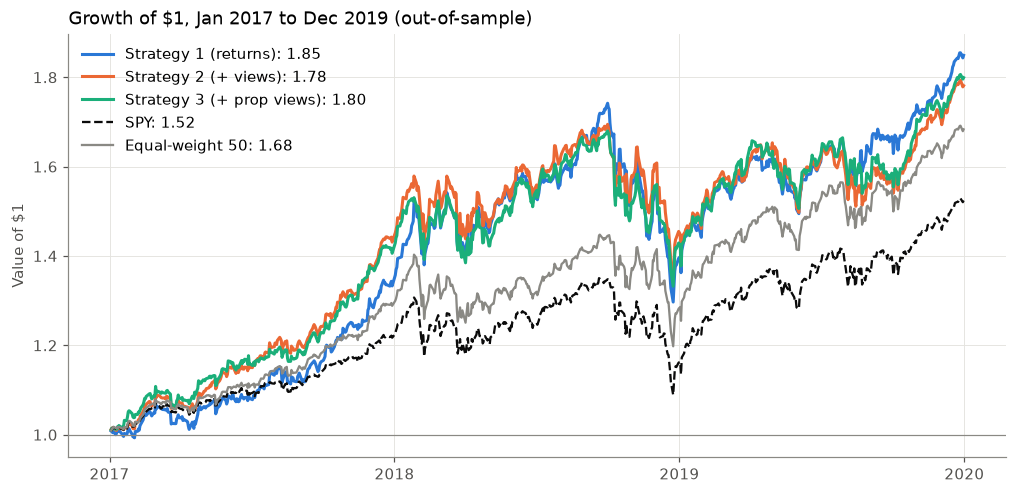

In [4]:
df_wealth = (1 + df_daily).cumprod()

fig, ax = plt.subplots(figsize=(11, 5))
for name in df_wealth.columns:
    ax.plot(df_wealth.index, df_wealth[name], color=colors[name], linewidth=2 if name.startswith('Strategy') else 1.5,
            linestyle='--' if name == 'SPY' else '-', label=f'{name}: {df_wealth[name].iloc[-1]:.2f}')
ax.axhline(1, color='#8a8984', linewidth=0.8)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.set_title('Growth of $1, Jan 2017 to Dec 2019 (out-of-sample)', loc='left')
ax.set_ylabel('Value of $1')
ax.legend(loc='upper left')
fig.savefig('figures/cumulative_returns.png')

## Performance

In [5]:
n_years = len(df_daily) / 252

df_performance = pd.DataFrame({'cumulative_return'     : df_wealth.iloc[-1] - 1,
                               'annualized_return'     : df_wealth.iloc[-1] ** (1 / n_years) - 1,
                               'annualized_volatility' : df_daily.std() * np.sqrt(252),
                               'sharpe_ratio'          : df_daily.mean() / df_daily.std() * np.sqrt(252),
                               'max_drawdown'          : (df_wealth / df_wealth.cummax().clip(lower=1) - 1).min(),
                               'hit_rate'              : (df_daily > 0).mean()})
df_performance.round(3)

,cumulative_return,annualized_return,annualized_volatility,sharpe_ratio,max_drawdown,hit_rate
Strategy 1 (returns),0.849,0.228,0.165,1.332,-0.255,0.578
Strategy 2 (+ views),0.781,0.213,0.158,1.301,-0.202,0.564
Strategy 3 (+ prop views),0.799,0.217,0.155,1.341,-0.207,0.558
SPY,0.524,0.151,0.128,1.163,-0.193,0.565
Equal-weight 50,0.683,0.190,0.130,1.407,-0.173,0.592


## Returns by year

In [6]:
df_yearly = df_daily.groupby(df_daily.index.year).apply(lambda returns: (1 + returns).prod() - 1)
df_yearly.round(3)

,Strategy 1 (returns),Strategy 2 (+ views),Strategy 3 (+ prop views),SPY,Equal-weight 50
date,,,,,
2017,0.333,0.431,0.406,0.217,0.288
2018,0.046,0.017,0.016,-0.046,-0.005
2019,0.326,0.224,0.259,0.312,0.313


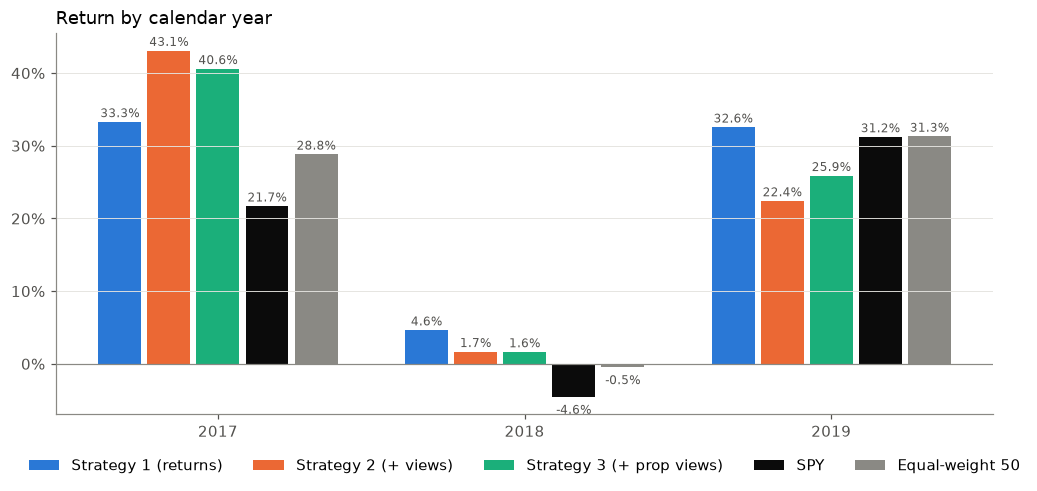

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.5))
bar_width = 0.16
for i, name in enumerate(df_yearly.columns):
    positions = np.arange(len(df_yearly)) + (i - 2) * bar_width
    ax.bar(positions, df_yearly[name], width=bar_width - 0.02, color=colors[name], label=name)
    for position, value in zip(positions, df_yearly[name]):
        ax.annotate(f'{value:.1%}', (position, value), xytext=(0, 3 if value >= 0 else -11),
                    textcoords='offset points', ha='center', fontsize=8, color='#52514e')
ax.axhline(0, color='#8a8984', linewidth=0.8)
ax.set_xticks(np.arange(len(df_yearly)), df_yearly.index)
ax.yaxis.set_major_formatter(lambda value, position: f'{value:.0%}')
ax.grid(axis='x', visible=False)
ax.set_title('Return by calendar year', loc='left')
ax.legend(ncol=5, loc='upper center', bbox_to_anchor=(0.5, -0.08))
fig.savefig('figures/returns_by_year.png')

## Information coefficient

In [8]:
df_ic = pd.DataFrame({strategy_names[strat_id]: df_predictions[[f'{ticker}_pred_{strat_id}' for ticker in stocks]]
                                                    .set_axis(stocks, axis=1)
                                                    .rank(axis=1)
                                                    .corrwith(df_stock_returns.rank(axis=1), axis=1)
                      for strat_id in [1, 2, 3]})

pd.DataFrame({'mean_ic'    : df_ic.mean(),
              't_stat'     : df_ic.mean() / df_ic.std() * np.sqrt(len(df_ic)),
              'share_ic_positive' : (df_ic > 0).mean()}).round(4)

,mean_ic,t_stat,share_ic_positive
Strategy 1 (returns),0.0099,1.1985,0.5265
Strategy 2 (+ views),0.0100,1.4126,0.5133
Strategy 3 (+ prop views),0.0099,1.4020,0.5424


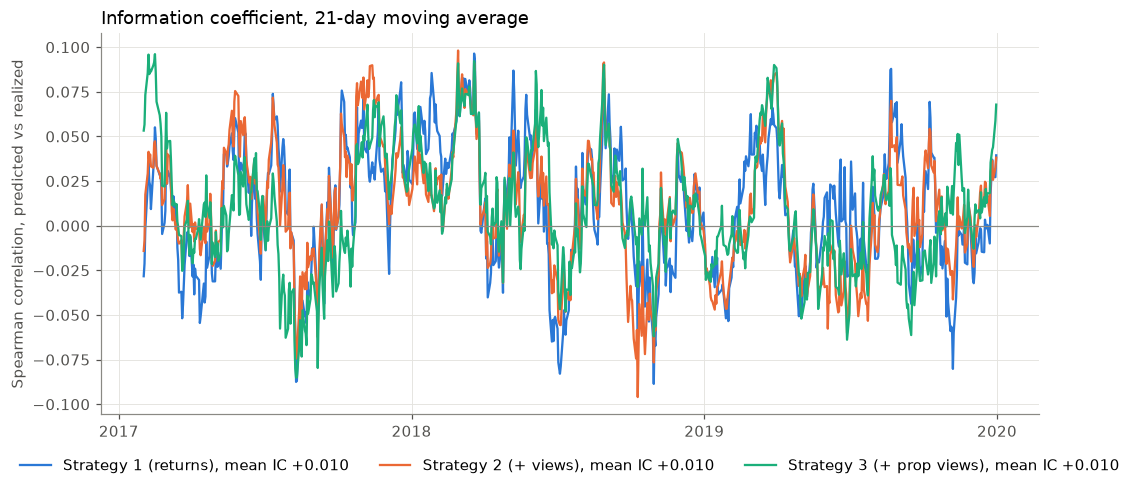

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for name in df_ic.columns:
    ax.plot(df_ic.index, df_ic[name].rolling(21).mean(), color=colors[name], linewidth=1.5,
            label=f'{name}, mean IC {df_ic[name].mean():+.3f}')
ax.axhline(0, color='#8a8984', linewidth=0.8)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.set_title('Information coefficient, 21-day moving average', loc='left')
ax.set_ylabel('Spearman correlation, predicted vs realized')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.08))
fig.savefig('figures/information_coefficient.png')

## Coefficient stability

In [10]:
df_coefficients['excludes_zero'] = (df_coefficients.ci_low > 0) | (df_coefficients.ci_high < 0)

attention_terms = [(2, 'lagged_views'), (3, 'lagged_views'), (3, 'lagged_prop_views')]

df_stability = (df_coefficients[df_coefficients[['model', 'term']].apply(tuple, axis=1).isin(attention_terms)]
                .groupby(['model', 'term', 'cycle'])
                .agg(mean_coef=('coef', 'mean'), share_excludes_zero=('excludes_zero', 'mean')))

df_stability.groupby(['model', 'term']).agg(mean_coef=('mean_coef', 'mean'),
                                            share_excludes_zero=('share_excludes_zero', 'mean'),
                                            cycles_mean_coef_positive=('mean_coef', lambda coefs: (coefs > 0).sum()))

mean_coef  share_excludes_zero  \
model term                                                   
2     lagged_views      -4.775233e-07             0.055000   
3     lagged_prop_views  8.038880e-02             0.067222   
      lagged_views      -2.666663e-06             0.055000   

                         cycles_mean_coef_positive  
model term                                          
2     lagged_views                              10  
3     lagged_prop_views                         29  
      lagged_views                               4

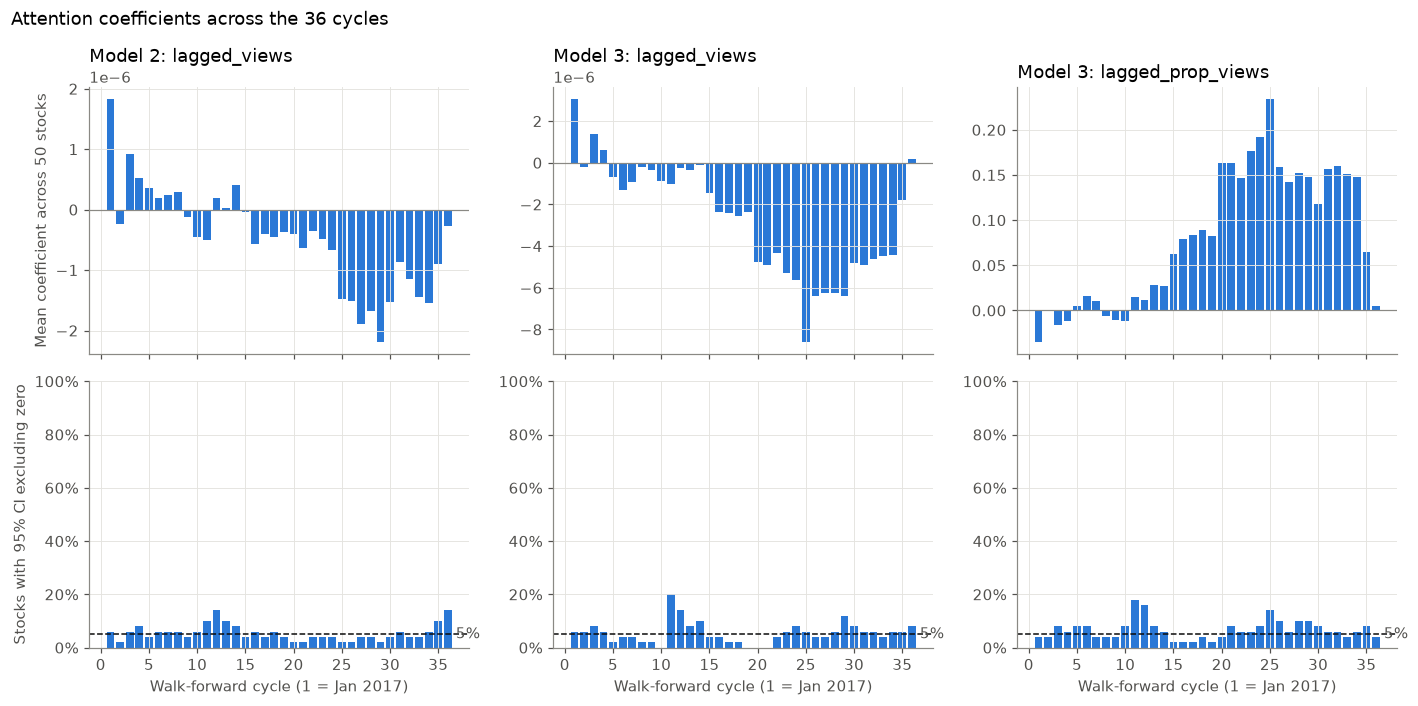

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for column, (model_id, term) in enumerate(attention_terms):
    df_term = df_stability.loc[(model_id, term)]
    axes[0, column].bar(df_term.index, df_term.mean_coef, color='#2a78d6', width=0.8)
    axes[0, column].axhline(0, color='#8a8984', linewidth=0.8)
    axes[0, column].set_title(f'Model {model_id}: {term}', loc='left')
    axes[1, column].bar(df_term.index, df_term.share_excludes_zero, color='#2a78d6', width=0.8)
    axes[1, column].axhline(0.05, color='#0b0b0b', linewidth=1, linestyle='--')
    axes[1, column].annotate('5%', (36.5, 0.05), xytext=(2, 0), textcoords='offset points', va='center', color='#52514e')
    axes[1, column].set_ylim(0, 1)
    axes[1, column].yaxis.set_major_formatter(lambda value, position: f'{value:.0%}')
    axes[1, column].set_xlabel('Walk-forward cycle (1 = Jan 2017)')
axes[0, 0].set_ylabel('Mean coefficient across 50 stocks')
axes[1, 0].set_ylabel('Stocks with 95% CI excluding zero')
fig.suptitle('Attention coefficients across the 36 cycles', x=0.01, ha='left')
fig.tight_layout()
fig.savefig('figures/coefficient_stability.png')

## Transaction costs

In [12]:
turnover = {}
for strat_id in [1, 2, 3]:
    df_strategy_predictions = df_predictions[[f'{ticker}_pred_{strat_id}' for ticker in stocks]].set_axis(stocks, axis=1)
    df_weights = (df_strategy_predictions.rank(axis=1, ascending=False, method='first') <= 10).astype(float) / 10
    print(strategy_names[strat_id], 'max difference to saved returns:',
          np.abs((df_weights * df_stock_returns).sum(axis=1) - df_daily[strategy_names[strat_id]]).max())
    turnover[strategy_names[strat_id]] = (df_weights - df_weights.shift(1)).abs().sum(axis=1) / 2
    turnover[strategy_names[strat_id]].iloc[0] = 1

df_turnover = pd.DataFrame(turnover)
df_turnover.describe().round(3)

Strategy 1 (returns) max difference to saved returns: 2.187919984075748e-16
Strategy 2 (+ views) max difference to saved returns: 2.3592239273284576e-16
Strategy 3 (+ prop views) max difference to saved returns: 2.2898349882893854e-16


,Strategy 1 (returns),Strategy 2 (+ views),Strategy 3 (+ prop views)
count,754.000,754.000,754.000
mean,0.202,0.191,0.187
std,0.119,0.117,0.114
min,0.000,0.000,0.000
25%,0.100,0.100,0.100
50%,0.200,0.200,0.200
75%,0.300,0.200,0.200
max,1.000,1.000,1.000


In [13]:
costs_bps = [0, 5, 10, 20]

df_net_cumulative = pd.DataFrame({cost: [(1 + df_daily[name] - df_turnover[name] * cost / 10000).prod() - 1 for name in df_turnover.columns]
                                  for cost in costs_bps},
                                 index=df_turnover.columns)
df_net_cumulative.columns = [f'{cost} bps' for cost in costs_bps]
df_net_cumulative.loc['SPY'] = df_performance.loc['SPY', 'cumulative_return']
df_net_cumulative.loc['Equal-weight 50'] = df_performance.loc['Equal-weight 50', 'cumulative_return']
df_net_cumulative.round(3)

,0 bps,5 bps,10 bps,20 bps
Strategy 1 (returns),0.849,0.713,0.588,0.363
Strategy 2 (+ views),0.781,0.658,0.543,0.336
Strategy 3 (+ prop views),0.799,0.676,0.562,0.356
SPY,0.524,0.524,0.524,0.524
Equal-weight 50,0.683,0.683,0.683,0.683


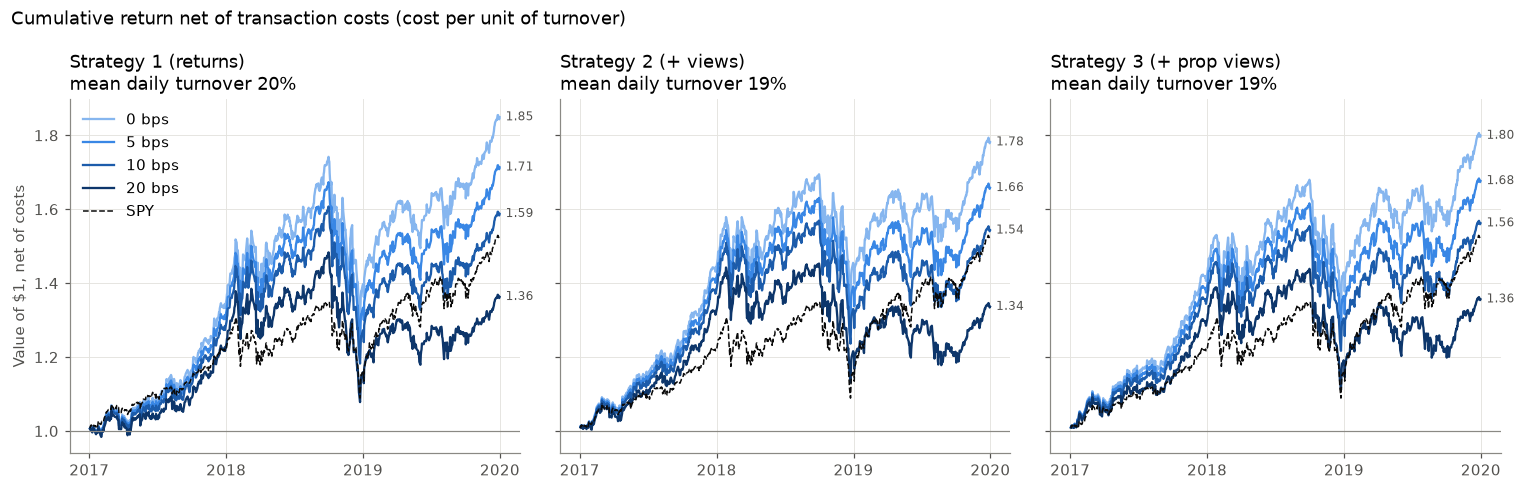

In [14]:
cost_colors = {0: '#86b6ef', 5: '#3987e5', 10: '#1c5cab', 20: '#0d366b'}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)
for ax, name in zip(axes, df_turnover.columns):
    for cost in costs_bps:
        net_wealth = (1 + df_daily[name] - df_turnover[name] * cost / 10000).cumprod()
        ax.plot(net_wealth.index, net_wealth, color=cost_colors[cost], linewidth=1.5, label=f'{cost} bps')
        ax.annotate(f'{net_wealth.iloc[-1]:.2f}', (net_wealth.index[-1], net_wealth.iloc[-1]),
                    xytext=(4, 0), textcoords='offset points', va='center', fontsize=8, color='#52514e')
    ax.plot(df_wealth.index, df_wealth.SPY, color=colors['SPY'], linewidth=1, linestyle='--', label='SPY')
    ax.axhline(1, color='#8a8984', linewidth=0.8)
    ax.set_title(f'{name}\nmean daily turnover {df_turnover[name].mean():.0%}', loc='left')
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[0].set_ylabel('Value of $1, net of costs')
axes[0].legend(loc='upper left')
fig.suptitle('Cumulative return net of transaction costs (cost per unit of turnover)', x=0.01, ha='left')
fig.tight_layout()
fig.savefig('figures/transaction_costs.png')

## Random portfolios

In [15]:
rng = np.random.default_rng(42)
n_portfolios = 10000

random_wealth = np.ones(n_portfolios)
for day_returns in df_stock_returns.to_numpy():
    picks = rng.random((n_portfolios, len(stocks))).argpartition(10, axis=1)[:, :10]
    random_wealth *= 1 + day_returns[picks].mean(axis=1)

random_cumulative = random_wealth - 1

df_percentiles = pd.DataFrame({'cumulative_return' : df_performance.cumulative_return,
                               'percentile'        : [(random_cumulative < value).mean() * 100 for value in df_performance.cumulative_return]})
df_percentiles.round(3)

,cumulative_return,percentile
Strategy 1 (returns),0.849,86.82
Strategy 2 (+ views),0.781,75.59
Strategy 3 (+ prop views),0.799,78.91
SPY,0.524,14.26
Equal-weight 50,0.683,51.89


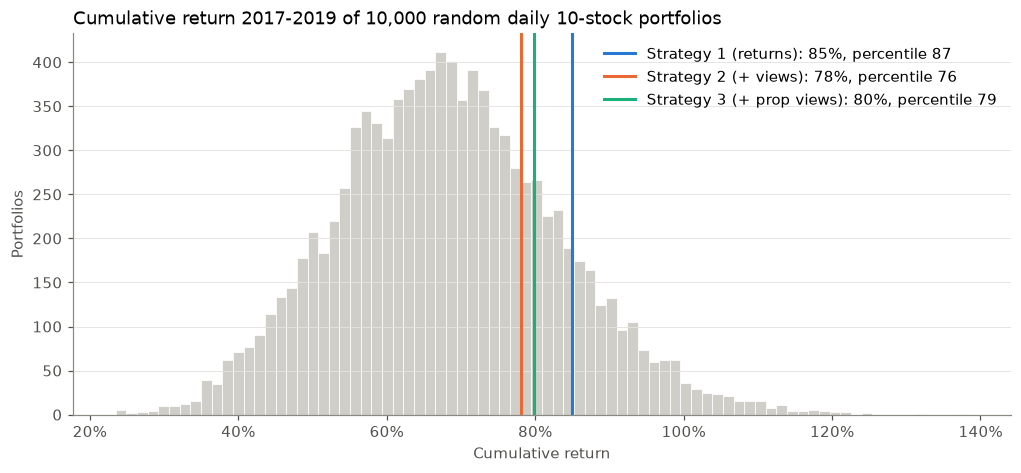

In [16]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.hist(random_cumulative, bins=80, color='#cfcec9', edgecolor='white', linewidth=0.5)
for name in df_turnover.columns:
    value = df_performance.loc[name, 'cumulative_return']
    ax.axvline(value, color=colors[name], linewidth=2,
               label=f'{name}: {value:.0%}, percentile {df_percentiles.loc[name, "percentile"]:.0f}')
ax.xaxis.set_major_formatter(lambda value, position: f'{value:.0%}')
ax.grid(axis='x', visible=False)
ax.set_title(f'Cumulative return 2017-2019 of {n_portfolios:,} random daily 10-stock portfolios', loc='left')
ax.set_xlabel('Cumulative return')
ax.set_ylabel('Portfolios')
ax.legend(loc='upper right')
fig.savefig('figures/random_portfolios.png')